### 1. Definição do Conjunto de Dados

O conjunto de dados escolhido foi o **Netflix Customer Churn & Engagement Analytics**, obtido na plataforma Kaggle. A base possui 5.000 registros e 14 atributos relacionados ao perfil dos clientes, tipo de assinatura, hábitos de visualização, mensalidade, forma de pagamento e preferência de gênero.

A variável-alvo é `churned`, que indica se o cliente abandonou o serviço (1) ou permaneceu como cliente (0). O objetivo desta análise é compreender as características do conjunto de dados, verificar a qualidade e a distribuição das informações e identificar os pré-processamentos necessários para uma futura aplicação de algoritmos de classificação.

In [1]:
# Importação
import os
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Download e Carregamento do Dataset
print("Dataset via Kagglehub")
path = kagglehub.dataset_download("zeyadmohamed26/netflix-customer-churn-and-engagement-analytics")

csv_file = [f for f in os.listdir(path) if f.endswith('.csv')][0]
caminho_completo = os.path.join(path, csv_file)

df = pd.read_csv(caminho_completo)
print(f"Dataset carregado com sucesso!\nNúmero de linhas e colunas: {df.shape}")

c:\Dev\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dataset via Kagglehub
Dataset carregado com sucesso!
Número de linhas e colunas: (5000, 14)


In [2]:
# Verificação da estrutura e dos tipos dos dados
print("Dimensões do dataset:", df.shape)
print("\nInformações sobre as colunas:")
df.info()
print("\nTipo de dado de cada atributo:")
display(df.dtypes.to_frame(name="Tipo de dado"))
print("\nResumo estatístico de todos os atributos:")
display(df.describe(include="all").T)

Dimensões do dataset: (5000, 14)

Informações sobre as colunas:
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   customer_id             5000 non-null   str    
 1   age                     5000 non-null   int64  
 2   gender                  5000 non-null   str    
 3   subscription_type       5000 non-null   str    
 4   watch_hours             5000 non-null   float64
 5   last_login_days         5000 non-null   int64  
 6   region                  5000 non-null   str    
 7   device                  5000 non-null   str    
 8   monthly_fee             5000 non-null   float64
 9   churned                 5000 non-null   int64  
 10  payment_method          5000 non-null   str    
 11  number_of_profiles      5000 non-null   int64  
 12  avg_watch_time_per_day  5000 non-null   float64
 13  favorite_genre          5000 non-null   

,Tipo de dado
customer_id,str
age,int64
gender,str
subscription_type,str
watch_hours,float64
last_login_days,int64
region,str
device,str
monthly_fee,float64
churned,int64



Resumo estatístico de todos os atributos:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id,5000,5000,a9b75100-82a8-427a-a208-72f24052884a,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,5000.0,NaN,NaN,NaN,43.8474,15.501128,18.0,30.0,44.0,58.0,70.0
gender,5000,3,Female,1711,NaN,NaN,NaN,NaN,NaN,NaN,NaN
subscription_type,5000,3,Premium,1693,NaN,NaN,NaN,NaN,NaN,NaN,NaN
watch_hours,5000.0,NaN,NaN,NaN,11.64945,12.014654,0.01,3.3375,8.0,16.03,110.4
last_login_days,5000.0,NaN,NaN,NaN,30.0898,17.536078,0.0,15.0,30.0,45.0,60.0
region,5000,6,South America,873,NaN,NaN,NaN,NaN,NaN,NaN,NaN
device,5000,5,Tablet,1048,NaN,NaN,NaN,NaN,NaN,NaN,NaN
monthly_fee,5000.0,NaN,NaN,NaN,13.6834,3.692062,8.99,8.99,13.99,17.99,17.99
churned,5000.0,NaN,NaN,NaN,0.503,0.500041,0.0,0.0,1.0,1.0,1.0


In [3]:
# 2. Verificação de Valores Ausentes
print("Valores ausentes em cada atributo:")
print(df.isnull().sum())

Valores ausentes em cada atributo:
customer_id               0
age                       0
gender                    0
subscription_type         0
watch_hours               0
last_login_days           0
region                    0
device                    0
monthly_fee               0
churned                   0
payment_method            0
number_of_profiles        0
avg_watch_time_per_day    0
favorite_genre            0
dtype: int64


**Valores Ausentes:** O dataset não tem qualquer dado em falta (todos retornaram 0 no `isnull()`). O nosso grupo não vai precisar aplicar técnicas de preenchimento ou remoção de linhas vazias.

In [4]:
# 3. Análise Estatística
display(df.describe())

,age,watch_hours,last_login_days,monthly_fee,churned,number_of_profiles,avg_watch_time_per_day
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,43.847400,11.649450,30.089800,13.683400,0.503000,3.024400,0.874800
std,15.501128,12.014654,17.536078,3.692062,0.500041,1.415841,2.619824
min,18.000000,0.010000,0.000000,8.990000,0.000000,1.000000,0.000000
25%,30.000000,3.337500,15.000000,8.990000,0.000000,2.000000,0.110000
50%,44.000000,8.000000,30.000000,13.990000,1.000000,3.000000,0.290000
75%,58.000000,16.030000,45.000000,17.990000,1.000000,4.000000,0.720000
max,70.000000,110.400000,60.000000,17.990000,1.000000,5.000000,98.420000


**Identificação de Outliers:** Prestando atenção à coluna `avg_watch_time_per_day` na tabela acima, o 3º quartil (75%) é de 0.72 horas, mas o valor máximo salta para impossíveis 98.42 (ninguém consegue assistir a 98 horas num só dia). Isto indica a presença de dados corrompidos ou *outliers* extremos. lidamos com estas anomalias no pré-processamento.

In [5]:
# 4. Balanceamento das Classes
print("Distribuição da classe alvo (churned):")
print(df['churned'].value_counts())

Distribuição da classe alvo (churned):
churned
1    2515
0    2485
Name: count, dtype: int64


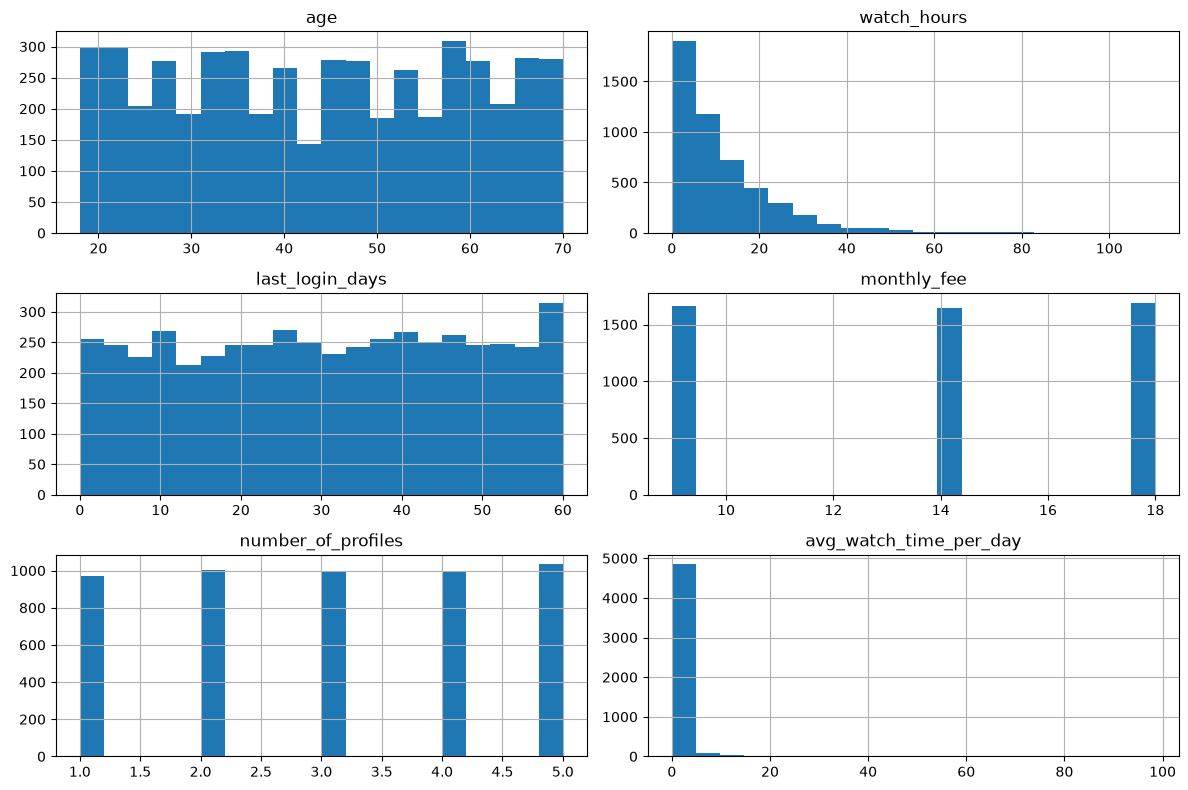


Distribuição de gender:
gender
Female    1711
Male      1654
Other     1635
Name: count, dtype: int64

Distribuição de subscription_type:
subscription_type
Premium     1693
Basic       1661
Standard    1646
Name: count, dtype: int64

Distribuição de region:
region
South America    873
Europe           867
North America    851
Asia             841
Africa           803
Oceania          765
Name: count, dtype: int64

Distribuição de device:
device
Tablet     1048
Laptop     1006
Mobile     1004
TV          993
Desktop     949
Name: count, dtype: int64

Distribuição de payment_method:
payment_method
Debit Card     1030
PayPal         1026
Crypto          995
Gift Card       976
Credit Card     973
Name: count, dtype: int64

Distribuição de favorite_genre:
favorite_genre
Drama          731
Documentary    729
Romance        725
Sci-Fi         720
Horror         713
Action         697
Comedy         685
Name: count, dtype: int64


In [6]:
# Distribuição dos principais atributos numéricos
colunas_numericas = [    
    "age",    
    "watch_hours",    
    "last_login_days",    
    "monthly_fee",    
    "number_of_profiles",    
    "avg_watch_time_per_day"
]
df[colunas_numericas].hist(bins=20, figsize=(12, 8))
plt.tight_layout()
plt.show()

# Distribuição dos atributos categóricos
colunas_categoricas = [    
    "gender",    
    "subscription_type",    
    "region",    
    "device",    
    "payment_method",    
    "favorite_genre"
]
for coluna in colunas_categoricas:    
    print(f"\nDistribuição de {coluna}:")    
    print(df[coluna].value_counts(dropna=False))

**Balanceamento Ideal:** A base apresenta uma distribuição equilibrada das classes, com 50,3% de clientes que abandonaram o serviço e 49,7% que permaneceram. Esse equilíbrio reduz a preocupação com problemas decorrentes do desbalanceamento, embora não garanta, por si só, a ausência de vieses nos modelos.

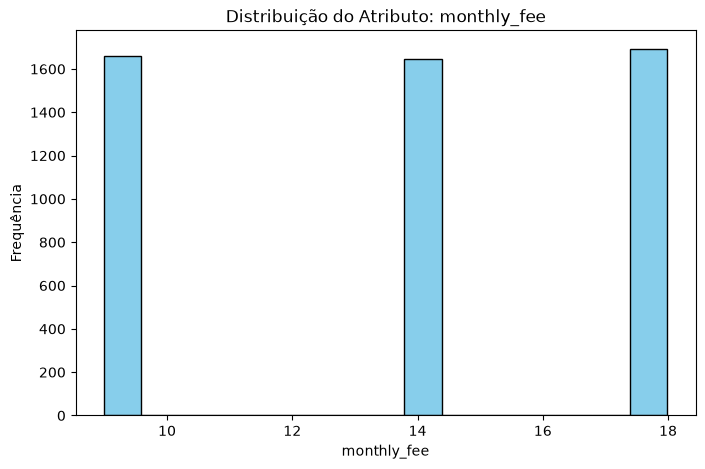

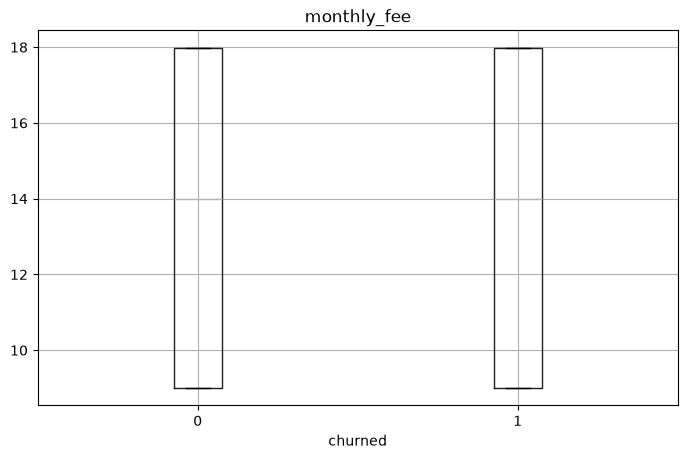

In [7]:
# 5. Estudo da Distribuição
coluna_numerica = 'monthly_fee'
coluna_alvo = 'churned'

# Histograma
plt.figure(figsize=(8, 5))
plt.hist(df[coluna_numerica].dropna(), bins=15, color='skyblue', edgecolor='black')
plt.xlabel(coluna_numerica)
plt.ylabel("Frequência")
plt.title(f"Distribuição do Atributo: {coluna_numerica}")
plt.show()

# Boxplot
df.boxplot(column=coluna_numerica, by=coluna_alvo, figsize=(8, 5))
plt.suptitle("")
plt.show()

**Análise da Mensalidade (`monthly_fee`):** 
Conforme o histograma gerado, as mensalidades agrupam-se em três faixas de valores distintos (aproximadamente $9, $14 e $18), o que reflete os planos padrão de subscrição. O *boxplot* demonstra que as caixas de dispersão e as medianas são idênticas tanto para os clientes que abandonaram (1) como para os que ficaram (0). Isto sugere que, de forma isolada, o valor da mensalidade pode não ser o fator mais determinante para o *churn* nesta base de dados específica.

## 6. Pré-Processamento de Dados

Para que os algoritmos de classificação consigam processar este conjunto de dados, precisamos transformar todas as informações numa matriz numérica (atributo-valor). Esta etapa inclui o tratamento de outliers identificados na análise exploratória, a codificação de variáveis de texto (categóricas) e a normalização das escalas.

### 6.1 Tratamento de Outliers
Como detectado na análise descritiva, a coluna `avg_watch_time_per_day` possui valores absurdos (ex: 98 horas num dia). Iremos limitar/ajustar estas anomalias utilizando o método de Capping baseado no Intervalo Interquartil (IQR), substituindo os valores extremos pelos limites superior e inferior, garantindo a qualidade da nossa matriz sem perder linhas de dados.

**Nota Metodológica sobre o Tratamento de Outliers:**
A aplicação do método IQR na variável `avg_watch_time_per_day` foi motivada pela presença de inconsistências físicas no dataset original (valores superiores a 24 horas/dia, com pico em 98,42h). O limite superior estatístico ($Q_3 + 1,5 \times IQR$) resultou em $1,635$ horas/dia, afetando $10,98\%$ da base (549 registos). Reconhece-se que consumos de 2 a 3 horas diárias representam padrões legítimos de utilização; contudo, optou-se pelo *capping* neste limiar para conter o impacto das anomalias extremas sem remover linhas da base. 

A variável watch_hours apresenta 238 registos acima do seu limite estatístico (35,07h), chegando a um máximo de 110 horas. No entanto, de acordo com a documentação oficial do dataset, esta variável reflete o consumo mensal. Um valor de 110 horas mensais equivale a cerca de 3,6 horas por dia, o que é um padrão de consumo perfeitamente plausível e realista para utilizadores da Netflix. Por não se tratarem de inconsistências ou erros de medição, optou-se por manter estes valores inalterados.

In [8]:
df_processado = df.copy()

# Binning (Agrupamento de idades)
bins = [17, 29, 44, 59, 70]
labels = ["18-29", "30-44", "45-59", "60-70"]
df_processado['age_group'] = pd.cut(df_processado['age'], bins=bins, labels=labels)
df_processado.drop('age', axis=1, inplace=True)

# Tratamento de Outliers (Aplicado no df_processado)
Q1 = df_processado['avg_watch_time_per_day'].quantile(0.25)
Q3 = df_processado['avg_watch_time_per_day'].quantile(0.75)
IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
# Tratamento de Outliers (Aplicado no df_processado)
# Em vez de IQR, usamos o limite máximo razoável com base na documentação do dataset (aprox. 5 horas)
limite_superior_diario = 5.0

df_processado['avg_watch_time_per_day'] = np.where(
    df_processado['avg_watch_time_per_day'] > limite_superior_diario,
    limite_superior_diario,
    df_processado['avg_watch_time_per_day']
)

### 6.2 Limpeza e Codificação de Variáveis Categóricas
A coluna `customer_id` é apenas um identificador único, não agregando valor preditivo ao modelo, logo será descartada. 
As colunas com texto (como `gender`, `subscription_type`, `region`, `device`, `payment_method`, e `favorite_genre`) precisam de ser convertidas em números. Utilizaremos a técnica **One-Hot Encoding** (através da função `get_dummies` do Pandas) para transformar estas categorias em colunas binárias (0 ou 1).

In [9]:
# Remoção da coluna de ID
df_processado = df_processado.drop('customer_id', axis=1)

# Identificação das colunas categóricas (Adicionado 'category' no filtro)
colunas_categoricas = df_processado.select_dtypes(
    include=['object', 'category', 'str']
).columns

# Aplicação do One-Hot Encoding
df_processado = pd.get_dummies(df_processado, columns=colunas_categoricas, drop_first=True)

# Converter as colunas booleanas geradas pelo get_dummies em inteiros (0 e 1)
colunas_bool = df_processado.select_dtypes(include=['bool']).columns
df_processado[colunas_bool] = df_processado[colunas_bool].astype(int)

print("Matriz atributo-valor após codificação:")
print(f"Número de colunas aumentou para: {df_processado.shape[1]}")
df_processado.head()

Matriz atributo-valor após codificação:
Número de colunas aumentou para: 32


,watch_hours,last_login_days,monthly_fee,churned,number_of_profiles,avg_watch_time_per_day,gender_Male,gender_Other,subscription_type_Premium,subscription_type_Standard,...,payment_method_PayPal,favorite_genre_Comedy,favorite_genre_Documentary,favorite_genre_Drama,favorite_genre_Horror,favorite_genre_Romance,favorite_genre_Sci-Fi,age_group_30-44,age_group_45-59,age_group_60-70
0,14.73,29,8.99,1,1,0.49,0,1,0,0,...,0,0,0,0,0,0,0,0,1,0
1,0.70,19,13.99,1,5,0.03,0,1,0,1,...,0,0,0,0,0,0,1,0,1,0
2,16.32,10,13.99,0,2,1.48,0,0,0,1,...,0,0,0,1,0,0,0,0,0,0
3,4.51,12,17.99,1,2,0.35,0,1,1,0,...,0,0,0,0,1,0,0,0,1,0
4,1.89,13,13.99,1,2,0.13,0,1,0,1,...,0,0,0,0,0,0,0,0,1,0


### 6.3 Normalização dos Dados
Os nossos atributos numéricos estão em escalas muito diferentes. Por exemplo, `watch_hours` tem valores dezenas de vezes maiores que `number_of_profiles`. Para evitar que algoritmos sensíveis à escala (como KNN) dem mais importância a variáveis apenas por terem números maiores, vamos normalizar as características numéricas utilizando a padronização (Média = 0, Desvio Padrão = 1).

In [10]:
from sklearn.preprocessing import StandardScaler

# Separar os atributos (X) do alvo/target (y)
X = df_processado.drop('churned', axis=1)
y = df_processado['churned']

# 'age' removido da lista de colunas numéricas
colunas_numericas_orig = ['watch_hours', 'last_login_days', 'monthly_fee', 'number_of_profiles', 'avg_watch_time_per_day']

scaler = StandardScaler()
X[colunas_numericas_orig] = scaler.fit_transform(X[colunas_numericas_orig])

print("Visualização final da Matriz Atributo-Valor Pré-processada:")
display(X.head())

df_final = pd.concat([X, y], axis=1)
df_final.to_csv('netflix_churn_pre_processado.csv', index=False)
print("Ficheiro 'netflix_churn_pre_processado.csv'")

df.to_csv('netflix_churn_original.csv', index=False)
print("Ficheiro 'netflix_churn_original.csv'")

Visualização final da Matriz Atributo-Valor Pré-processada:


,watch_hours,last_login_days,monthly_fee,number_of_profiles,avg_watch_time_per_day,gender_Male,gender_Other,subscription_type_Premium,subscription_type_Standard,region_Asia,...,payment_method_PayPal,favorite_genre_Comedy,favorite_genre_Documentary,favorite_genre_Drama,favorite_genre_Horror,favorite_genre_Romance,favorite_genre_Sci-Fi,age_group_30-44,age_group_45-59,age_group_60-70
0,0.256425,-0.062152,-1.271341,-1.429965,-0.187730,0,1,0,0,0,...,0,0,0,0,0,0,0,0,1,0
1,-0.911432,-0.632462,0.083051,1.395494,-0.619930,0,1,0,1,0,...,0,0,0,0,0,0,1,0,1,0
2,0.388777,-1.145741,0.083051,-0.723600,0.742437,0,0,0,1,1,...,0,0,0,1,0,0,0,0,0,0
3,-0.594288,-1.031679,1.166565,-0.723600,-0.319269,0,1,1,0,0,...,0,0,0,0,1,0,0,0,1,0
4,-0.812377,-0.974648,0.083051,-0.723600,-0.525973,0,1,0,1,0,...,0,0,0,0,0,0,0,0,1,0


Ficheiro 'netflix_churn_pre_processado.csv'
Ficheiro 'netflix_churn_original.csv'
